# Week 9 Data Gate — AI Career Predictor + Skill Gap Analyzer

Notebook นี้ทำ 4 ขั้นตอนของ Data Gate กับข้อมูล O*NET ในโฟลเดอร์ `datasets`

1. **Data Collection** — โหลดและสรุปข้อมูลทั้ง 8 ไฟล์
2. **EDA** — สำรวจความครบถ้วน การกระจาย และความสัมพันธ์ของข้อมูล
3. **Data Cleaning / Preparation** — ทำความสะอาดและแปลงเป็น Occupation Vector สำหรับ Career Matching และ Skill Gap
4. **Split Strategy** — วางวิธีแบ่งข้อมูลและวัดผล
5. **Data Leakage และข้อจำกัด** — ตรวจจุดเสี่ยงด้วยโค้ดจริง

> วางไฟล์ notebook นี้ไว้ในโฟลเดอร์เดียวกับไฟล์ `.xlsx` ทั้ง 8 ไฟล์ ผลลัพธ์ทั้งหมดจะถูกบันทึกใน `data_gate_output/`

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

DATA_DIR = Path(".")
OUT_DIR = Path("data_gate_output"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

# chart style: one blue for single series, fixed categorical order for multi-series
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ae", "axes.titleweight": "bold", "axes.titlesize": 12,
    "font.size": 10, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data Collection

แหล่งข้อมูล: **O*NET Resource Center** (U.S. Department of Labor) สัญญาอนุญาต **CC BY 4.0** ต้องใส่เครดิต O*NET ในงานและในเว็บแอป

ข้อมูลเป็น **long format** คือ 1 แถว = 1 อาชีพ × 1 องค์ประกอบ (ทักษะ/ความรู้/ความสามารถ) × 1 สเกล

In [2]:
FILES = {
    "Abilities": "Abilities.xlsx",
    "Knowledge": "Knowledge.xlsx",
    "Essential Skills": "Essential Skills.xlsx",
    "Career Interest Types": "Career Interest Types.xlsx",
    "Work Styles": "Work Styles.xlsx",
    "Software Skills": "Software Skills.xlsx",
    "Task Statements": "Task Statements.xlsx",
    "Occupation Data": "Occupation Data.xlsx",
}
raw = {name: pd.read_excel(DATA_DIR / f) for name, f in FILES.items()}

ROLE = {
    "Abilities": "ความสามารถ → User Skill Vector",
    "Knowledge": "ความรู้ → User Skill Vector",
    "Essential Skills": "ทักษะพื้นฐาน → User Skill Vector",
    "Career Interest Types": "ความสนใจ RIASEC → Interests",
    "Work Styles": "ลักษณะการทำงาน → Work preferences",
    "Software Skills": "ซอฟต์แวร์/เทคโนโลยี → Technical skills",
    "Task Statements": "งานที่ทำจริง → ให้ LLM อธิบายผล (ไม่ใช่ feature)",
    "Occupation Data": "ชื่อ + คำอธิบายอาชีพ (ไม่ใช่ feature)",
}
rows = []
for name, df in raw.items():
    rows.append({
        "file": name, "rows": len(df), "columns": df.shape[1],
        "occupations": df["O*NET-SOC Code"].nunique(),
        "elements": df["Element Name"].nunique() if "Element Name" in df else None,
        "scales": ", ".join(sorted(df["Scale ID"].unique())) if "Scale ID" in df else "",
        "duplicate_rows": int(df.duplicated().sum()),
        "role_in_system": ROLE[name],
    })
collection_summary = pd.DataFrame(rows)
collection_summary.to_csv(OUT_DIR / "01_collection_summary.csv", index=False)
display(collection_summary)

,file,rows,columns,occupations,elements,scales,duplicate_rows,role_in_system
0,Abilities,94640,15,910,52.0,"IM, LV",0,ความสามารถ → User Skill Vector
1,Knowledge,60060,15,910,33.0,"IM, LV",0,ความรู้ → User Skill Vector
2,Essential Skills,18200,15,910,10.0,"IM, LV",0,ทักษะพื้นฐาน → User Skill Vector
3,Career Interest Types,8307,9,923,9.0,"IH, OI",0,ความสนใจ RIASEC → Interests
4,Work Styles,37422,9,891,21.0,"DR, WI",0,ลักษณะการทำงาน → Work preferences
5,Software Skills,31821,7,923,134.0,,0,ซอฟต์แวร์/เทคโนโลยี → Technical skills
6,Task Statements,18838,8,923,NaN,,0,งานที่ทำจริง → ให้ LLM อธิบายผล (ไม่ใช่ feature)
7,Occupation Data,1016,3,1016,NaN,,0,ชื่อ + คำอธิบายอาชีพ (ไม่ใช่ feature)


**Data dictionary (คอลัมน์หลักที่ใช้)**

| คอลัมน์ | ความหมาย |
| --- | --- |
| `O*NET-SOC Code` | รหัสอาชีพ เช่น `15-2051.00` = Data Scientists (2 หลักแรก = กลุ่มอาชีพหลัก) |
| `Element Name` | ชื่อทักษะ/ความรู้/ความสามารถ |
| `Scale ID` | `IM` = Importance (1–5), `LV` = Level (0–7), `OI` = Occupational Interest (1–7), `WI` = Work Styles Impact |
| `Data Value` | คะแนนของอาชีพนั้นในองค์ประกอบนั้น |
| `Recommend Suppress` | `Y` = O*NET แนะนำว่าไม่ควรใช้ค่า (ความแม่นยำต่ำ) |
| `Not Relevant` | `Y` = องค์ประกอบนี้ไม่เกี่ยวกับอาชีพ |
| `Hot Technology` / `In Demand` | ซอฟต์แวร์ที่ตลาดต้องการสูง |

**Target ของระบบ:** อาชีพ (O*NET-SOC Code) ที่สอดคล้องกับผู้ใช้มากที่สุด จัดอันดับ Top 5 ตาม Matching Score — ข้อมูลชุดนี้เป็นข้อมูลระดับอาชีพ ไม่มีข้อมูลผู้ใช้และไม่มี label

## 2. EDA (Exploratory Data Analysis)

### 2.1 ความครบถ้วน: แต่ละไฟล์มีอาชีพครบกี่อาชีพ

In [3]:
occ = raw["Occupation Data"].copy()
occ["major"] = occ["O*NET-SOC Code"].str[:2]
MAJOR = {"11":"Management","13":"Business & Financial","15":"Computer & Mathematical","17":"Architecture & Engineering",
 "19":"Life, Physical & Social Science","21":"Community & Social Service","23":"Legal","25":"Education & Library",
 "27":"Arts, Design & Media","29":"Healthcare Practitioners","31":"Healthcare Support","33":"Protective Service",
 "35":"Food Preparation & Serving","37":"Building & Grounds","39":"Personal Care & Service","41":"Sales",
 "43":"Office & Admin Support","45":"Farming, Fishing & Forestry","47":"Construction & Extraction",
 "49":"Installation & Repair","51":"Production","53":"Transportation & Moving","55":"Military"}
occ["major_name"] = occ["major"].map(MAJOR)

rating_files = ["Abilities","Knowledge","Essential Skills","Career Interest Types","Work Styles","Software Skills","Task Statements"]
sets = {f: set(raw[f]["O*NET-SOC Code"]) for f in rating_files}
all_codes = set(occ["O*NET-SOC Code"])
core = sets["Abilities"] & sets["Knowledge"] & sets["Essential Skills"] & sets["Career Interest Types"]
in_all = set.intersection(*sets.values())
no_data = all_codes - set.union(*sets.values())

print(f"อาชีพทั้งหมดใน Occupation Data      : {len(all_codes):,}")
print(f"มีคะแนนครบ 4 ไฟล์หลัก (Ab/Kn/Sk/RIASEC): {len(core):,}")
print(f"มีข้อมูลครบทั้ง 7 ไฟล์               : {len(in_all):,}")
print(f"ไม่มีข้อมูลคะแนนเลย                  : {len(no_data):,}")

print("\nอาชีพที่ไม่มีข้อมูลคะแนน แยกตามกลุ่ม (top 8):")
display(occ[occ["O*NET-SOC Code"].isin(no_data)]["major_name"].value_counts().head(8).to_frame("occupations"))
print("ตัวอย่างชื่อ:", occ[occ["O*NET-SOC Code"].isin(no_data)]["Title"].head(6).tolist())

อาชีพทั้งหมดใน Occupation Data      : 1,016
มีคะแนนครบ 4 ไฟล์หลัก (Ab/Kn/Sk/RIASEC): 910
มีข้อมูลครบทั้ง 7 ไฟล์               : 878
ไม่มีข้อมูลคะแนนเลย                  : 93

อาชีพที่ไม่มีข้อมูลคะแนน แยกตามกลุ่ม (top 8):


,occupations
major_name,
Military,19
Healthcare Practitioners,7
Production,7
"Life, Physical & Social Science",6
Education & Library,6
"Arts, Design & Media",5
Transportation & Moving,5
Community & Social Service,4


ตัวอย่างชื่อ: ['Education Administrators, All Other', 'Personal Service Managers, All Other', 'Managers, All Other', 'Business Operations Specialists, All Other', 'Financial Specialists, All Other', 'Computer Occupations, All Other']


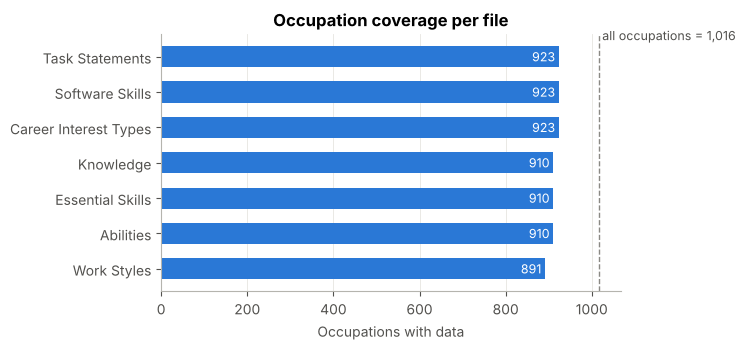

In [4]:
cov = pd.Series({f: len(s) for f, s in sets.items()}).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(cov.index, cov.values, color=BLUE, height=0.6)
ax.axvline(len(all_codes), color=GRAY, ls="--", lw=1)
ax.text(len(all_codes), len(cov)-0.4, f" all occupations = {len(all_codes):,}", color="#52514e", va="center", fontsize=9)
for i, v in enumerate(cov.values): ax.text(v - 8, i, f"{v:,}", va="center", ha="right", color="white", fontsize=9)
ax.set_xlabel("Occupations with data"); ax.set_title("Occupation coverage per file")
ax.grid(axis="y", visible=False)
savefig("01_coverage_per_file"); plt.show()

### 2.2 ค่าหาย, Recommend Suppress และ Not Relevant

In [5]:
qrows = []
for f in ["Abilities","Knowledge","Essential Skills"]:
    d = raw[f]
    qrows.append({
        "file": f, "rows": len(d),
        "Recommend Suppress = Y": int((d["Recommend Suppress"] == "Y").sum()),
        "Recommend Suppress missing": int(d["Recommend Suppress"].isna().sum()),
        "Not Relevant = Y (LV rows)": int((d["Not Relevant"] == "Y").sum()),
        "LV = 0": int(((d["Scale ID"] == "LV") & (d["Data Value"] == 0)).sum()),
        "Std Error missing": int(d["Standard Error"].isna().sum()),
        "N missing": int(d["N"].isna().sum()),
    })
quality = pd.DataFrame(qrows)
quality.to_csv(OUT_DIR / "02_quality_flags.csv", index=False)
display(quality)

print("ค่าหายในไฟล์อื่น:")
for f in ["Career Interest Types","Work Styles","Software Skills","Task Statements","Occupation Data"]:
    n = raw[f].isna().sum(); print(f"  {f:22s}", n[n > 0].to_dict() or "ไม่มีค่าหาย")

,file,rows,Recommend Suppress = Y,Recommend Suppress missing,Not Relevant = Y (LV rows),LV = 0,Std Error missing,N missing
0,Abilities,94640,55,0,7572,5865,0,0
1,Knowledge,60060,4947,16434,6082,495,16962,594
2,Essential Skills,18200,21,0,298,165,0,0


ค่าหายในไฟล์อื่น:
  Career Interest Types  ไม่มีค่าหาย
  Work Styles            ไม่มีค่าหาย
  Software Skills        ไม่มีค่าหาย
  Task Statements        {'Task Type': 418, 'Incumbents Responding': 587}
  Occupation Data        ไม่มีค่าหาย


- **Not Relevant = Y** ไม่ใช่ค่าหาย หมายถึงองค์ประกอบนั้นไม่เกี่ยวกับอาชีพ → ใช้ Level = 0
- **Recommend Suppress = Y** คือค่าที่ O*NET บอกว่าไม่น่าเชื่อถือ (ตัวอย่างน้อยหรือ error สูง) → ต้องจัดการใน Cleaning
- ค่าหายของ Standard Error / CI ไม่กระทบ เพราะไม่ได้ใช้เป็น feature

### 2.3 การกระจายของคะแนน Level และ Importance

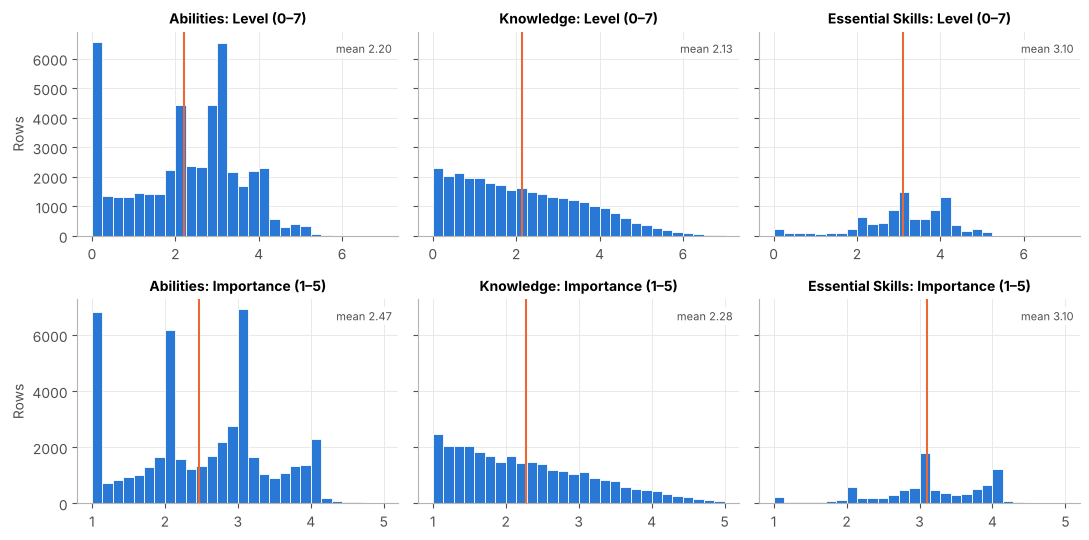

count  mean   std  min   25%   50%   75%   max
                 Scale ID                                                  
Abilities        IM        47320.0  2.47  0.92  1.0  1.88  2.62  3.12  5.00
                 LV        47320.0  2.20  1.33  0.0  1.12  2.38  3.12  6.00
Knowledge        IM        30030.0  2.28  0.93  1.0  1.49  2.12  2.91  5.00
                 LV        30030.0  2.13  1.49  0.0  0.87  1.91  3.21  6.97
Essential Skills IM         9100.0  3.10  0.77  1.0  2.75  3.12  3.75  5.00
                 LV         9100.0  3.10  1.07  0.0  2.62  3.12  4.00  6.00

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharey="row")
for j, f in enumerate(["Abilities","Knowledge","Essential Skills"]):
    d = raw[f]
    for i, (sc, rng, lab) in enumerate([("LV", (0, 7), "Level (0–7)"), ("IM", (1, 5), "Importance (1–5)")]):
        v = d.loc[d["Scale ID"] == sc, "Data Value"]
        ax = axes[i, j]
        ax.hist(v, bins=28, range=rng, color=BLUE, edgecolor="white", linewidth=0.6)
        ax.axvline(v.mean(), color=ORANGE, lw=1.5)
        ax.text(0.98, 0.95, f"mean {v.mean():.2f}", transform=ax.transAxes, ha="right", va="top", color="#52514e", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
        ax.set_title(f"{f}: {lab}", fontsize=10)
axes[0,0].set_ylabel("Rows"); axes[1,0].set_ylabel("Rows")
savefig("02_level_importance_distribution"); plt.show()

desc = pd.concat({f: raw[f].groupby("Scale ID")["Data Value"].describe().round(2) for f in ["Abilities","Knowledge","Essential Skills"]})
display(desc)

**สิ่งที่พบ:** Abilities และ Knowledge มีค่าเฉลี่ยต่ำ (ราว 2.1–2.2 จาก 7) และมีค่า 0 จำนวนมากจาก Not Relevant โดย Knowledge เบ้ขวาชัดเจน (มีเพียงบางอาชีพที่ต้องการความรู้ระดับสูง) ส่วน Essential Skills อยู่กลาง ๆ (เฉลี่ย 3.1) เพราะทุกอาชีพใช้ทักษะพื้นฐาน → ตอนเปรียบเทียบกับผู้ใช้ต้องปรับสเกลให้เท่ากัน

### 2.4 Importance กับ Level ซ้ำซ้อนกันหรือไม่

,file,pairs,"pearson_r(IM, LV)"
0,Abilities,47320,0.976
1,Knowledge,30030,0.962
2,Essential Skills,9100,0.954


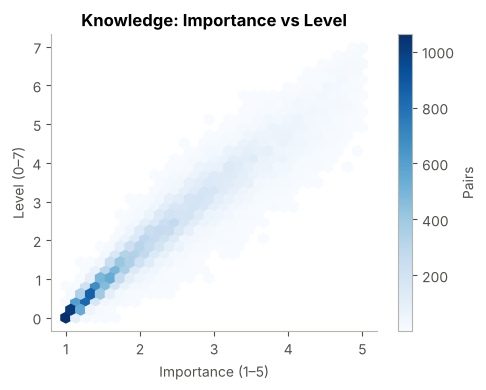

In [7]:
corr_rows = []
for f in ["Abilities","Knowledge","Essential Skills"]:
    w = raw[f].pivot_table(index=["O*NET-SOC Code","Element Name"], columns="Scale ID", values="Data Value").dropna()
    corr_rows.append({"file": f, "pairs": len(w), "pearson_r(IM, LV)": round(w["IM"].corr(w["LV"]), 3)})
display(pd.DataFrame(corr_rows))

w = raw["Knowledge"].pivot_table(index=["O*NET-SOC Code","Element Name"], columns="Scale ID", values="Data Value").dropna()
fig, ax = plt.subplots(figsize=(5, 4))
hb = ax.hexbin(w["IM"], w["LV"], gridsize=30, cmap="Blues", mincnt=1)
ax.set_xlabel("Importance (1–5)"); ax.set_ylabel("Level (0–7)"); ax.set_title("Knowledge: Importance vs Level")
plt.colorbar(hb, ax=ax, label="Pairs"); ax.grid(False)
savefig("03_importance_vs_level"); plt.show()

**สิ่งที่พบ:** IM กับ LV สัมพันธ์กันสูงมาก ใช้ทั้งคู่เป็น feature ก็ซ้ำซ้อน → ใช้ **Level** เป็นเวกเตอร์หลัก (บอกว่าต้องเก่งแค่ไหน ซึ่งตรงกับกราฟ Skill Gap) และใช้ **Importance** เป็นน้ำหนักจัดลำดับว่าควรพัฒนาทักษะไหนก่อน

### 2.5 สมดุลของกลุ่มอาชีพ

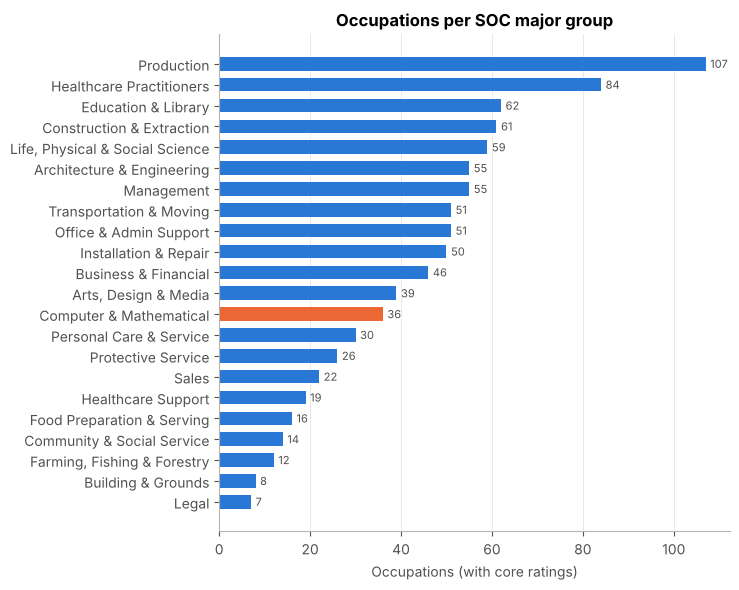

มากสุด Production = 107 | น้อยสุด Legal = 7 | Computer & Mathematical = 36


In [8]:
grp = occ[occ["O*NET-SOC Code"].isin(core)]["major_name"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 6))
colors = [ORANGE if n == "Computer & Mathematical" else BLUE for n in grp.index]
ax.barh(grp.index, grp.values, color=colors, height=0.65)
for i, v in enumerate(grp.values): ax.text(v + 1, i, str(v), va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Occupations (with core ratings)"); ax.set_title("Occupations per SOC major group")
ax.grid(axis="y", visible=False)
savefig("04_major_group_balance"); plt.show()
print(f"มากสุด {grp.idxmax()} = {grp.max()} | น้อยสุด {grp.idxmin()} = {grp.min()} | Computer & Mathematical = {grp.get('Computer & Mathematical')}")

**สิ่งที่พบ:** กลุ่มอาชีพไม่สมดุล อาชีพสาย Production/Healthcare มีจำนวนมาก แต่สาย Computer & Mathematical (กลุ่มเป้าหมายหลักของนักศึกษา) มีน้อยกว่า ระบบ matching ไม่ได้เรียนรู้จากสัดส่วนนี้โดยตรง แต่ต้องระวังตอนสร้างผู้ใช้จำลองและตอนวัดผล (ใช้ stratified split)

### 2.6 ความสนใจ (RIASEC) และ Work Styles

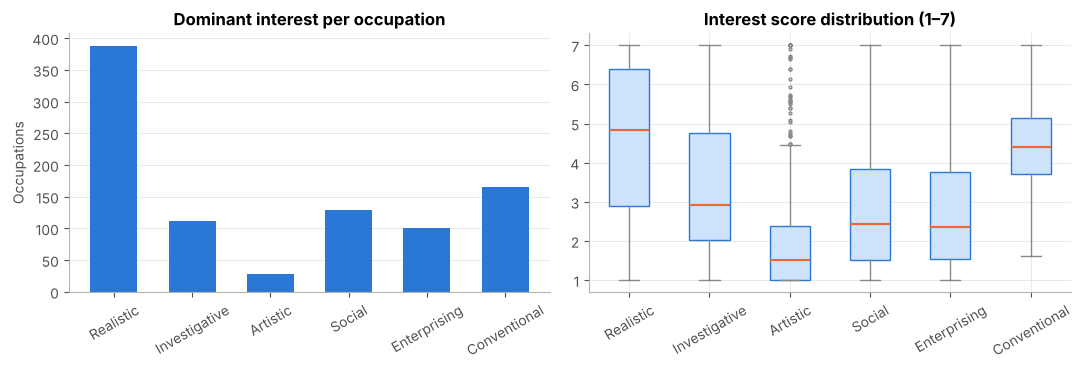

Work Styles: 891 อาชีพ × 21 ลักษณะ | ช่วงค่า WI -1.42 ถึง 3.00


,mean WI
Element Name,
Dependability,2.44
Attention to Detail,2.33
Integrity,1.79
Cautiousness,1.74
Perseverance,1.51
Stress Tolerance,1.47
Achievement Orientation,1.45
Cooperation,1.44


In [9]:
ci = raw["Career Interest Types"]
oi = ci[ci["Scale ID"] == "OI"].pivot(index="O*NET-SOC Code", columns="Element Name", values="Data Value")
RIASEC = ["Realistic","Investigative","Artistic","Social","Enterprising","Conventional"]
oi = oi[RIASEC]
first = oi.idxmax(axis=1).value_counts().reindex(RIASEC)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(first.index, first.values, color=BLUE, width=0.6)
axes[0].set_title("Dominant interest per occupation"); axes[0].set_ylabel("Occupations")
axes[0].tick_params(axis="x", rotation=30); axes[0].grid(axis="x", visible=False)
axes[1].boxplot([oi[c] for c in RIASEC], tick_labels=RIASEC, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=ORANGE, lw=1.5),
                whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY), flierprops=dict(markersize=2, markeredgecolor=GRAY))
axes[1].set_title("Interest score distribution (1–7)"); axes[1].tick_params(axis="x", rotation=30)
savefig("05_riasec"); plt.show()

ws = raw["Work Styles"]
wi = ws[ws["Scale ID"] == "WI"].pivot(index="O*NET-SOC Code", columns="Element Name", values="Data Value")
print(f"Work Styles: {wi.shape[0]} อาชีพ × {wi.shape[1]} ลักษณะ | ช่วงค่า WI {wi.values.min():.2f} ถึง {wi.values.max():.2f}")
display(wi.mean().sort_values(ascending=False).round(2).to_frame("mean WI").head(8))

### 2.7 ซอฟต์แวร์และเทคโนโลยี

ไฟล์ Software Skills มีชื่อซอฟต์แวร์หลายพันชื่อ จึงจัดกลุ่มเป็น **skill tag** ที่ผู้ใช้ประเมินตัวเองได้ เช่น Python, SQL, Git

ชื่อซอฟต์แวร์ไม่ซ้ำ: 8,753 | Hot Technology: 36% ของแถว | In Demand: 8%


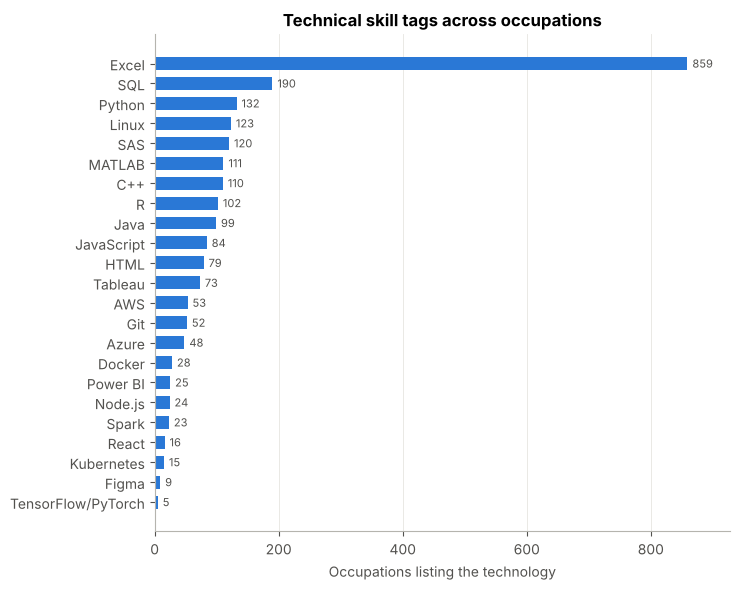

,occupations,share_in_demand
Excel,859,0.39
SQL,190,0.11
Python,132,0.50
Linux,123,0.14
SAS,120,0.10
MATLAB,111,0.17
C++,110,0.22
R,102,0.27
Java,99,0.17
JavaScript,84,0.16


In [10]:
sw = raw["Software Skills"].copy()
print(f"ชื่อซอฟต์แวร์ไม่ซ้ำ: {sw['Workplace Example'].nunique():,} | Hot Technology: {(sw['Hot Technology']=='Y').mean():.0%} ของแถว | In Demand: {(sw['In Demand']=='Y').mean():.0%}")

TECH_TAGS = {
    "Python": r"^Python$", "SQL": r"(?<!No)SQL", "R": r"^R$", "Java": r"^(Oracle )?Java$",
    "JavaScript": r"^JavaScript$|^JavaScript framework", "C++": r"^C\+\+$", "Git": r"^Git$|^GitHub$|^GitLab$",
    "Docker": r"^Docker$", "Kubernetes": r"^Kubernetes$", "AWS": r"^Amazon Web Services|^AWS ",
    "Azure": r"^Microsoft Azure", "Linux": r"^Linux$|^Red Hat Enterprise Linux$", "React": r"^React( Native| Redux)?$",
    "Node.js": r"^Node\.js$", "HTML": r"[Hh]ypertext markup language", "Tableau": r"^Tableau$",
    "Power BI": r"^Microsoft Power BI$", "Excel": r"^Microsoft Excel$", "Spark": r"^Apache Spark$|^PySpark$",
    "TensorFlow/PyTorch": r"^TensorFlow$|^PyTorch$", "MATLAB": r"MATLAB", "SAS": r"^SAS$|^SAS ", "Figma": r"^Figma$",
}
for tag, pat in TECH_TAGS.items():
    sw[f"tag::{tag}"] = sw["Workplace Example"].str.contains(pat, regex=True)
tag_cols = [c for c in sw.columns if c.startswith("tag::")]
tag_occ = pd.Series({c[5:]: sw.loc[sw[c], "O*NET-SOC Code"].nunique() for c in tag_cols}).sort_values()
tag_demand = pd.Series({c[5:]: (sw.loc[sw[c], "In Demand"] == "Y").mean() if sw[c].any() else 0 for c in tag_cols})

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(tag_occ.index, tag_occ.values, color=BLUE, height=0.65)
for i, (t, v) in enumerate(tag_occ.items()): ax.text(v + 8, i, f"{v}", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, tag_occ.max() * 1.08); ax.set_xlabel("Occupations listing the technology")
ax.set_title("Technical skill tags across occupations"); ax.grid(axis="y", visible=False)
savefig("06_software_tags"); plt.show()
display(pd.DataFrame({"occupations": tag_occ, "share_in_demand": tag_demand.round(2)}).sort_values("occupations", ascending=False).head(12))

### 2.8 ตัวอย่างโปรไฟล์อาชีพ: Data Scientists vs Software Developers

ตรวจว่าข้อมูลแยกอาชีพได้สมเหตุสมผลหรือไม่ (sanity check)

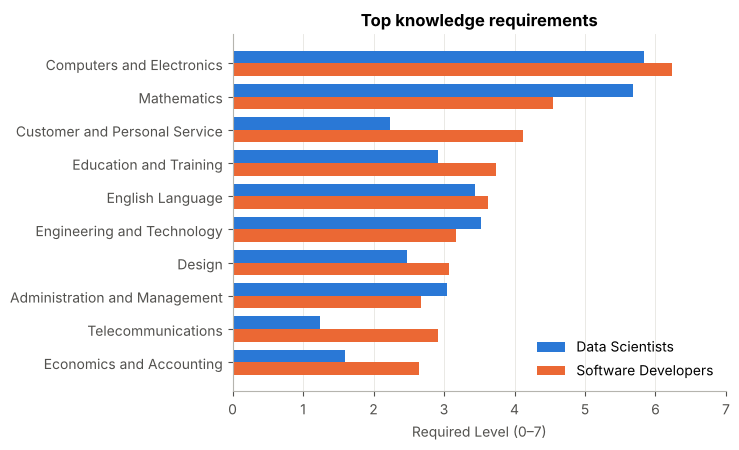

In [11]:
def level_profile(code, f):
    d = raw[f]; d = d[(d["O*NET-SOC Code"] == code) & (d["Scale ID"] == "LV")]
    return d.set_index("Element Name")["Data Value"]
A, B = "15-2051.00", "15-1252.00"
names = occ.set_index("O*NET-SOC Code")["Title"]
kn_cmp = pd.DataFrame({names[A]: level_profile(A, "Knowledge"), names[B]: level_profile(B, "Knowledge")})
kn_cmp = kn_cmp.loc[kn_cmp.max(axis=1).sort_values(ascending=False).index[:10]].iloc[::-1]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
y = np.arange(len(kn_cmp)); h = 0.38
ax.barh(y + h/2, kn_cmp.iloc[:, 0], height=h, color=BLUE, label=kn_cmp.columns[0])
ax.barh(y - h/2, kn_cmp.iloc[:, 1], height=h, color=ORANGE, label=kn_cmp.columns[1])
ax.set_yticks(y); ax.set_yticklabels(kn_cmp.index); ax.set_xlim(0, 7)
ax.set_xlabel("Required Level (0–7)"); ax.set_title("Top knowledge requirements"); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
savefig("07_profile_example"); plt.show()

## 3. Data Cleaning / Preparation

| ขั้นตอน | ทำอะไร | เหตุผล |
| --- | --- | --- |
| 3.1 | Recommend Suppress = Y → ตั้งเป็นค่าหาย | O*NET ระบุว่าค่าไม่น่าเชื่อถือ |
| 3.2 | Not Relevant = Y → Level = 0 | ไม่เกี่ยวกับอาชีพ ไม่ใช่ค่าหาย |
| 3.3 | เติมค่าหายด้วย median ของกลุ่มอาชีพเดียวกัน | อาชีพในกลุ่มเดียวกันมีโปรไฟล์ใกล้กัน ดีกว่าใช้ median รวม |
| 3.4 | Pivot long → wide (1 แถว = 1 อาชีพ) | ได้ Occupation Vector สำหรับ matching |
| 3.5 | Normalize เป็น 0–100 | เทียบกับคะแนนผู้ใช้และใช้กับกราฟ Skill Gap ได้ตรง |
| 3.6 | สร้าง skill tag จากซอฟต์แวร์ | ลดชื่อซอฟต์แวร์หลายพันชื่อให้เหลือทักษะที่ผู้ใช้ประเมินได้ |
| 3.7 | ตรวจแถวซ้ำและอาชีพที่โปรไฟล์ซ้ำกัน | ป้องกันผลแนะนำซ้ำและปัญหาตอนวัดผล |

In [12]:
def clean_rating(f):
    d = raw[f].copy()
    n0 = len(d)
    suppressed = d["Recommend Suppress"].eq("Y")
    d.loc[suppressed, "Data Value"] = np.nan                                   # 3.1
    not_rel = d["Not Relevant"].eq("Y") & d["Scale ID"].eq("LV")
    d.loc[not_rel, "Data Value"] = 0.0                                          # 3.2
    d["major"] = d["O*NET-SOC Code"].str[:2]
    grp_med = d.groupby(["major", "Element Name", "Scale ID"])["Data Value"].transform("median")
    glob_med = d.groupby(["Element Name", "Scale ID"])["Data Value"].transform("median")
    n_missing = int(d["Data Value"].isna().sum())
    d["Data Value"] = d["Data Value"].fillna(grp_med).fillna(glob_med)         # 3.3
    d["domain"] = f
    log = {"file": f, "rows": n0, "suppressed→NaN": int(suppressed.sum()), "not_relevant→0": int(not_rel.sum()),
           "imputed": n_missing, "missing_after": int(d["Data Value"].isna().sum())}
    return d[["O*NET-SOC Code","Title","domain","Element ID","Element Name","Scale ID","Data Value"]], log

cleaned, logs = {}, []
for f in ["Abilities","Knowledge","Essential Skills"]:
    cleaned[f], lg = clean_rating(f); logs.append(lg)
cleaning_log = pd.DataFrame(logs)
cleaning_log.to_csv(OUT_DIR / "03_cleaning_log.csv", index=False)
display(cleaning_log)

,file,rows,suppressed→NaN,not_relevant→0,imputed,missing_after
0,Abilities,94640,55,7572,51,0
1,Knowledge,60060,4947,6082,1250,0
2,Essential Skills,18200,21,298,20,0


In [13]:
# 3.4–3.5 Long table for Skill Gap (Importance + Level, Level scaled 0–100)
long = pd.concat(cleaned.values())
req = long.pivot_table(index=["O*NET-SOC Code","Title","domain","Element Name"], columns="Scale ID", values="Data Value").reset_index()
req.columns.name = None
req = req.rename(columns={"IM": "importance_1_5", "LV": "level_0_7"})
req["required_level_0_100"] = (req["level_0_7"] / 7 * 100).round(1)
req["importance_0_100"] = ((req["importance_1_5"] - 1) / 4 * 100).round(1)
req = req[req["O*NET-SOC Code"].isin(core)]
req.to_csv(OUT_DIR / "occupation_requirements_long.csv", index=False)
print(f"occupation_requirements_long.csv: {len(req):,} แถว ({req['O*NET-SOC Code'].nunique()} อาชีพ × {len(req) // req['O*NET-SOC Code'].nunique()} องค์ประกอบ)")
display(req.head())

occupation_requirements_long.csv: 86,450 แถว (910 อาชีพ × 95 องค์ประกอบ)


,O*NET-SOC Code,Title,domain,Element Name,importance_1_5,level_0_7,required_level_0_100,importance_0_100
0,11-1011.00,Chief Executives,Abilities,Arm-Hand Steadiness,1.38,0.50,7.1,9.5
1,11-1011.00,Chief Executives,Abilities,Auditory Attention,2.12,2.00,28.6,28.0
2,11-1011.00,Chief Executives,Abilities,Category Flexibility,3.50,4.00,57.1,62.5
3,11-1011.00,Chief Executives,Abilities,Control Precision,1.75,0.75,10.7,18.8
4,11-1011.00,Chief Executives,Abilities,Deductive Reasoning,4.12,4.75,67.9,78.0


In [14]:
# Wide Occupation Vector
def wide_level(f, prefix):
    d = cleaned[f]; d = d[d["Scale ID"] == "LV"]
    w = d.pivot(index="O*NET-SOC Code", columns="Element Name", values="Data Value") / 7 * 100
    return w.add_prefix(prefix)

X_ab, X_kn, X_sk = wide_level("Abilities", "ab::"), wide_level("Knowledge", "kn::"), wide_level("Essential Skills", "sk::")
X_ri = ((oi - 1) / 6 * 100).add_prefix("ri::")                                  # RIASEC 1–7 → 0–100
wi_min, wi_max = wi.values.min(), wi.values.max()
X_ws = ((wi - wi_min) / (wi_max - wi_min) * 100).add_prefix("ws::")             # Work Styles → 0–100

# 3.6 software tags: 100 = listed (In Demand counts the same; flag kept separately)
tags = sw.groupby("O*NET-SOC Code")[tag_cols].any().astype(int) * 100
tags.columns = ["tech::" + c[5:] for c in tags.columns]

core_codes = sorted(core)
features = (X_ab.join([X_kn, X_sk, X_ri], how="inner")).loc[core_codes]
features = features.join(X_ws, how="left").join(tags, how="left")
features["has_work_styles"] = features.filter(like="ws::").notna().all(axis=1).astype(int)
features["has_software"] = features.index.isin(tags.index).astype(int)
ws_cols = features.filter(like="ws::").columns
features[ws_cols] = features[ws_cols].fillna(features[ws_cols].median())       # 19-ish occupations without Work Styles
features[tags.columns] = features[tags.columns].fillna(0)
features = features.round(2)

CORE_COLS = list(X_ab.columns) + list(X_kn.columns) + list(X_sk.columns) + list(X_ri.columns)
print(f"Occupation Vector: {features.shape[0]} อาชีพ × {features.shape[1]} คอลัมน์")
print(f"  core matching vector: {len(CORE_COLS)} มิติ (Abilities {X_ab.shape[1]} + Knowledge {X_kn.shape[1]} + Skills {X_sk.shape[1]} + RIASEC 6)")
print(f"  Work Styles {len(ws_cols)} | tech tags {tags.shape[1]} | ไม่มี Work Styles {int((features['has_work_styles']==0).sum())} อาชีพ (เติม median) | ไม่มี software {int((features['has_software']==0).sum())} อาชีพ")
print(f"  ค่าหายคงเหลือ: {int(features.isna().sum().sum())}")

Occupation Vector: 910 อาชีพ × 147 คอลัมน์
  core matching vector: 101 มิติ (Abilities 52 + Knowledge 33 + Skills 10 + RIASEC 6)
  Work Styles 21 | tech tags 23 | ไม่มี Work Styles 32 อาชีพ (เติม median) | ไม่มี software 0 อาชีพ
  ค่าหายคงเหลือ: 0


In [15]:
# 3.7 duplicates
dup_vec = features[CORE_COLS].duplicated(keep=False)
print(f"แถวซ้ำในไฟล์ต้นฉบับ: {int(collection_summary['duplicate_rows'].sum())} | อาชีพที่ core vector ซ้ำกันทุกค่า: {int(dup_vec.sum())}")

meta = occ.set_index("O*NET-SOC Code").loc[features.index, ["Title","Description","major","major_name"]]
features.to_csv(OUT_DIR / "occupation_features.csv")
meta.to_csv(OUT_DIR / "occupation_meta.csv")
sw_out = sw[["O*NET-SOC Code","Title","Workplace Example","Hot Technology","In Demand"] + tag_cols]
sw_out.to_csv(OUT_DIR / "occupation_software.csv", index=False)

funnel = pd.DataFrame({"step": ["Occupation Data", "มีข้อมูลคะแนนอย่างน้อย 1 ไฟล์", "ครบ 4 ไฟล์หลัก → Occupation Vector"],
                       "occupations": [len(all_codes), len(all_codes) - len(no_data), features.shape[0]]})
display(funnel)

แถวซ้ำในไฟล์ต้นฉบับ: 0 | อาชีพที่ core vector ซ้ำกันทุกค่า: 0


,step,occupations
0,Occupation Data,1016
1,มีข้อมูลคะแนนอย่างน้อย 1 ไฟล์,923
2,ครบ 4 ไฟล์หลัก → Occupation Vector,910


## 4. Split Strategy

ข้อมูลนี้ **1 อาชีพ = 1 แถว** และไม่มีข้อมูลผู้ใช้ จึงแบ่ง train/test แบบสุ่มแถวอาชีพไม่ได้ (อาชีพที่อยู่ใน test จะไม่มีอยู่ในระบบให้แนะนำ) แนวทางที่ใช้:

| ชุดข้อมูล | ที่มา | ใช้ทำอะไร |
| --- | --- | --- |
| **Reference set** | Occupation Vector ทุกอาชีพ | ฐานข้อมูลที่ระบบใช้เปรียบเทียบ ไม่ถูกแบ่ง |
| **Synthetic train / validation** | ผู้ใช้จำลองจาก Occupation Vector + noise แบ่ง stratified ตามอาชีพ 70/15 | ปรับน้ำหนัก feature / เทรน classifier |
| **Synthetic test** | ผู้ใช้จำลอง 15% ที่เหลือ | ตรวจระบบเบื้องต้น (ผลจะสูงเกินจริง ดูข้อ 5) |
| **Real-user test** | คนจริงที่รู้อาชีพตัวเอง เช่น รุ่นพี่ที่ทำงานแล้ว | วัดผลจริงครั้งสุดท้าย ห้ามใช้ปรับโมเดล |

**Metric:** Top-1 accuracy, **Top-5 accuracy** (อาชีพจริงติด Top 5 ที่แนะนำ) และ Top-5 ระดับกลุ่มอาชีพ

In [16]:
Xref = features[CORE_COLS].values.astype(float)
y_codes = np.asarray(features.index, dtype=object)
rng = np.random.default_rng(SEED)

def make_users(n_per_occ=10, noise_sd=15, bias=0.0, seed=SEED):
    r = np.random.default_rng(seed)
    U = np.repeat(Xref, n_per_occ, axis=0)
    U = U + bias + r.normal(0, noise_sd, U.shape)
    return np.clip(U, 0, 100), np.repeat(y_codes, n_per_occ)

U, yU = make_users()
idx = np.arange(len(U))
i_train, i_tmp = train_test_split(idx, test_size=0.30, stratify=yU, random_state=SEED)
i_val, i_test = train_test_split(i_tmp, test_size=0.50, stratify=yU[i_tmp], random_state=SEED)
split_sizes = pd.DataFrame({"split": ["train","validation","test"], "users": [len(i_train), len(i_val), len(i_test)],
                            "occupations": [len(set(yU[i])) for i in (i_train, i_val, i_test)]})
split_sizes["share"] = (split_sizes["users"] / len(U)).round(2)
display(split_sizes)

cols_out = CORE_COLS
for name, ii in [("train", i_train), ("val", i_val), ("test", i_test)]:
    pd.DataFrame(U[ii].round(1), columns=cols_out).assign(true_code=yU[ii]).to_csv(OUT_DIR / f"synthetic_users_{name}.csv", index=False)

,split,users,occupations,share
0,train,6370,910,0.70
1,validation,1365,910,0.15
2,test,1365,910,0.15


In [17]:
def cosine_topk(Q, R, k=5):
    Qn = Q / np.linalg.norm(Q, axis=1, keepdims=True); Rn = R / np.linalg.norm(R, axis=1, keepdims=True)
    S = Qn @ Rn.T
    return np.argsort(-S, axis=1)[:, :k]

def top5_group(top, y):
    tm = np.array([[c[:2] for c in row] for row in top]); ym = np.array([c[:2] for c in y])
    return float((tm == ym[:, None]).any(axis=1).mean())

def evaluate(Q, y, R=Xref, codes=y_codes):
    top = codes[cosine_topk(Q, R, 5)]
    return {"top1": float((top[:, 0] == y).mean()), "top5": float((top == y[:, None]).any(axis=1).mean()),
            "top5_major_group": top5_group(top, y)}

# Approach A: matching (no training) — evaluate on validation and test
res = pd.DataFrame({
    "A. Matching (cosine), validation": evaluate(U[i_val], yU[i_val]),
    "A. Matching (cosine), test": evaluate(U[i_test], yU[i_test]),
}).T

# Approach B: nearest-centroid learned on train only (scaler fitted on train only)
scaler = StandardScaler().fit(U[i_train])
cent = pd.DataFrame(scaler.transform(U[i_train])).groupby(yU[i_train]).mean()
def nc_eval(ii):
    Z = scaler.transform(U[ii]); C = cent.values
    d = ((Z[:, None, :] - C[None, :, :]) ** 2).sum(-1)
    top = np.asarray(cent.index, dtype=object)[np.argsort(d, axis=1)[:, :5]]; y = yU[ii]
    return {"top1": float((top[:, 0] == y).mean()), "top5": float((top == y[:, None]).any(axis=1).mean()),
            "top5_major_group": top5_group(top, y)}
res.loc["B. Nearest centroid (train→test)"] = nc_eval(i_test)
res = res.round(3)
res.to_csv(OUT_DIR / "04_split_results_synthetic.csv")
display(res)

,top1,top5,top5_major_group
"A. Matching (cosine), validation",0.963,0.996,1.000
"A. Matching (cosine), test",0.963,0.997,1.000
B. Nearest centroid (train→test),0.781,0.949,0.992


**อ่านผล:** ทั้งสองแนวทางได้ผลสูงบนผู้ใช้จำลอง เพราะผู้ใช้จำลองสร้างจากเวกเตอร์อาชีพเดียวกับที่ระบบใช้เปรียบเทียบ ตัวเลขนี้จึงใช้ได้แค่ตรวจว่า pipeline ทำงานถูก **ไม่ใช่ความแม่นยำจริง** (พิสูจน์ในข้อ 5.2)

**แผน Real-user test set**

| หัวข้อ | แผน |
| --- | --- |
| ผู้เข้าร่วม | คนทำงานจริงอย่างน้อย 30 คน ครอบคลุมหลายกลุ่มอาชีพ (เน้นสาย IT/Data) |
| วิธีเก็บ | ทำแบบประเมินเดียวกับในเว็บแอป แล้วบันทึกอาชีพจริง map เป็นรหัส O*NET-SOC |
| การใช้ | ใช้วัดผลครั้งสุดท้ายครั้งเดียว ไม่ใช้ปรับน้ำหนักหรือเลือก feature |
| Metric | Top-5 accuracy, Top-5 ระดับกลุ่มอาชีพ และ feedback ความพึงพอใจ |

## 5. Data Leakage และข้อจำกัด

### 5.1 Fit scaler ก่อน split

In [18]:
scaler_all = StandardScaler().fit(U)                  # WRONG: sees validation/test
scaler_train = StandardScaler().fit(U[i_train])       # RIGHT: train only
diff = np.abs(scaler_all.mean_ - scaler_train.mean_)
print(f"ค่าเฉลี่ยที่ scaler เรียนรู้ต่างกันสูงสุด {diff.max():.3f} คะแนน (เฉลี่ย {diff.mean():.3f})")
print("→ ในข้อมูลนี้ผลต่างเล็ก แต่หลักการคือ fit ทุกขั้นตอน (scaler, PCA, imputer, น้ำหนัก) กับ train เท่านั้น")
print("  ส่วน imputation ใน 3.3 ทำบน reference set ของอาชีพ ซึ่งไม่ได้ถูกแบ่ง จึงไม่รั่วไป test ของผู้ใช้")

ค่าเฉลี่ยที่ scaler เรียนรู้ต่างกันสูงสุด 0.276 คะแนน (เฉลี่ย 0.074)
→ ในข้อมูลนี้ผลต่างเล็ก แต่หลักการคือ fit ทุกขั้นตอน (scaler, PCA, imputer, น้ำหนัก) กับ train เท่านั้น
  ส่วน imputation ใน 3.3 ทำบน reference set ของอาชีพ ซึ่งไม่ได้ถูกแบ่ง จึงไม่รั่วไป test ของผู้ใช้


### 5.2 ผู้ใช้จำลองทำให้ผลสูงเกินจริง

ทดสอบว่าเมื่อผู้ใช้จริงตอบไม่แม่น (noise มากขึ้น) หรือประเมินตัวเองสูง/ต่ำกว่าจริงทั้งหมด (bias) ความแม่นยำจะเปลี่ยนแค่ไหน

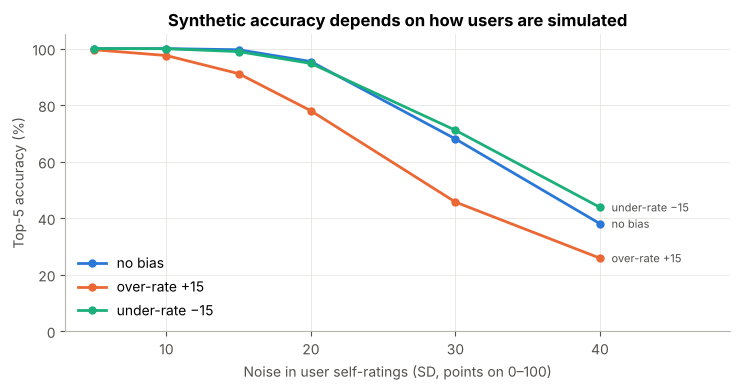

scenario,no bias,over-rate +15,under-rate −15
noise_sd,,,
5,1.000,0.996,1.000
10,1.000,0.975,1.000
15,0.996,0.911,0.989
20,0.954,0.780,0.948
30,0.680,0.457,0.711
40,0.380,0.258,0.438


In [19]:
rows = []
for sd in [5, 10, 15, 20, 30, 40]:
    for bias, lab in [(0, "no bias"), (15, "over-rate +15"), (-15, "under-rate −15")]:
        Q, y = make_users(n_per_occ=3, noise_sd=sd, bias=bias, seed=SEED + 1)
        r = evaluate(Q, y); rows.append({"noise_sd": sd, "scenario": lab, **r})
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "05_noise_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
for (lab, g), c in zip(sens.groupby("scenario", sort=False), [BLUE, ORANGE, AQUA]):
    ax.plot(g["noise_sd"], g["top5"] * 100, marker="o", ms=5, lw=2, color=c, label=lab)
    ax.text(g["noise_sd"].iloc[-1] + 0.8, g["top5"].iloc[-1] * 100, lab, color="#52514e", fontsize=8, va="center")
ax.set_xlabel("Noise in user self-ratings (SD, points on 0–100)"); ax.set_ylabel("Top-5 accuracy (%)")
ax.set_ylim(0, 105); ax.set_xlim(3, 49); ax.set_title("Synthetic accuracy depends on how users are simulated")
ax.legend(frameon=False, loc="lower left")
savefig("08_noise_sensitivity"); plt.show()
display(sens.pivot(index="noise_sd", columns="scenario", values="top5").round(3))

**สิ่งที่พบ:** ความแม่นยำขึ้นกับสมมติฐานตอนสร้างผู้ใช้จำลองเกือบทั้งหมด ถ้าสมมติว่าผู้ใช้ตอบใกล้ความจริง ผลจะดูดีมาก → นี่คือ leakage ที่สำคัญที่สุดของโปรเจกต์ จึงต้องมี **Real-user test set**

### 5.3 อาชีพที่โปรไฟล์ใกล้กันมาก

In [20]:
Rn = Xref / np.linalg.norm(Xref, axis=1, keepdims=True)
S = Rn @ Rn.T; np.fill_diagonal(S, 0)
iu = np.triu_indices_from(S, k=1)
pairs = pd.DataFrame({"a": y_codes[iu[0]], "b": y_codes[iu[1]], "cosine": S[iu]})
for thr in [0.99, 0.995]:
    print(f"คู่อาชีพที่ cosine > {thr}: {int((pairs['cosine'] > thr).sum()):,} คู่")
top_pairs = pairs.nlargest(10, "cosine").assign(a_title=lambda d: d["a"].map(names), b_title=lambda d: d["b"].map(names))
display(top_pairs[["a_title","b_title","cosine"]].round(4))

คู่อาชีพที่ cosine > 0.99: 12 คู่
คู่อาชีพที่ cosine > 0.995: 0 คู่


,a_title,b_title,cosine
180009,Neuropsychologists,Clinical Neuropsychologists,0.9939
273959,Physician Assistants,Nurse Practitioners,0.9928
991,Chief Sustainability Officers,Sustainability Specialists,0.9925
215461,"Atmospheric, Earth, Marine, and Space Sciences Teachers, Postsecondary","Environmental Science Teachers, Postsecondary",0.9919
292810,Physical Medicine and Rehabilitation Physicians,Sports Medicine Physicians,0.9918
133519,Materials Engineers,Materials Scientists,0.9916
123658,Water/Wastewater Engineers,Environmental Engineers,0.9915
178668,Clinical and Counseling Psychologists,Marriage and Family Therapists,0.9909
325606,Police and Sheriff's Patrol Officers,Transit and Railroad Police,0.9908
195465,Occupational Health and Safety Specialists,Occupational Health and Safety Technicians,0.9905


**สิ่งที่พบ:** หลายอาชีพมีโปรไฟล์เกือบเหมือนกัน (มักเป็นสายงานย่อยของกันและกัน) Top-1 จึงพลาดได้แม้ระบบถูกในเชิงความหมาย → ใช้ **Top-5** และ **Top-5 ระดับกลุ่มอาชีพ** เป็น metric หลัก

### 5.4 ตรวจว่าไม่มี feature ที่บอกคำตอบ

In [21]:
text_like = [c for c in features.columns if features[c].dtype == object]
forbidden = [c for c in CORE_COLS if re.search(r"title|description|task|code", c, re.I)]
print("คอลัมน์ข้อความใน feature matrix:", text_like or "ไม่มี")
print("feature ที่มาจาก Title/Description/Task/Code:", forbidden or "ไม่มี")
print("Task Statements และ Description ใช้เฉพาะให้ LLM อธิบายผล ไม่ได้อยู่ในเวกเตอร์ matching")

train_keys = set(map(lambda r: r.tobytes(), U[i_train].round(1)))
overlap = sum(r.tobytes() in train_keys for r in U[i_test].round(1))
print(f"ผู้ใช้จำลองที่ซ้ำกันระหว่าง train และ test: {overlap}")

คอลัมน์ข้อความใน feature matrix: ไม่มี
feature ที่มาจาก Title/Description/Task/Code: ไม่มี
Task Statements และ Description ใช้เฉพาะให้ LLM อธิบายผล ไม่ได้อยู่ในเวกเตอร์ matching
ผู้ใช้จำลองที่ซ้ำกันระหว่าง train และ test: 0


### 5.5 ข้อจำกัดของข้อมูล

In [22]:
dates = pd.to_datetime(pd.concat([raw[f]["Date"] for f in ["Abilities","Knowledge","Essential Skills"]]), format="%m/%Y")
lim = pd.DataFrame([
    ("ไม่มีข้อมูลผู้ใช้และ label", "ประเมินผลจริงไม่ได้จากข้อมูลชุดนี้", "เก็บ Real-user test set"),
    ("ตลาดแรงงานสหรัฐฯ", "ทักษะที่ต้องการอาจต่างจากตลาดไทย และชื่ออาชีพต่างจากที่ใช้ในไทย", "แสดงคำเตือน + map ชื่ออาชีพไทยในเว็บแอป"),
    (f"Essential Skills มี {X_sk.shape[1]} ทักษะพื้นฐาน", "ไม่มีทักษะเชิงเทคนิค เช่น Programming", "ใช้ tech tags จาก Software Skills / เพิ่มไฟล์ Skills ฉบับเต็ม"),
    (f"{len(no_data)} อาชีพไม่มีคะแนน", "ระบบแนะนำอาชีพเหล่านี้ไม่ได้", "ระบุในขอบเขตโปรเจกต์"),
    (f"ค่า Suppress {int(cleaning_log['suppressed→NaN'].sum()):,} ค่าถูกตัด และเติมค่าหาย {int(cleaning_log['imputed'].sum()):,} ค่า", "ค่าที่เติมเป็นค่าประมาณจากกลุ่มอาชีพ", "บันทึกใน cleaning log"),
    ("คะแนนผู้ใช้มาจากการประเมินตนเอง", "อาจสูงหรือต่ำกว่าจริง (ดู 5.2)", "ใช้คำอธิบายระดับ (anchor) แบบ O*NET ในแบบประเมิน"),
    ("Work Styles / Interests สร้างด้วย AI/ML + ผู้เชี่ยวชาญ", "ไม่ใช่ผลสำรวจคนทำงานโดยตรง", "ใช้เป็น feature เสริม น้ำหนักต่ำกว่า"),
    (f"ข้อมูลอัปเดตต่างปี ({dates.min():%m/%Y} – {dates.max():%m/%Y})", "บางอาชีพข้อมูลเก่ากว่าอาชีพอื่น", "ระบุรอบข้อมูลที่ใช้"),
    ("กลุ่มอาชีพไม่สมดุล", f"Computer & Mathematical มีแค่ {grp.get('Computer & Mathematical')} อาชีพ", "stratified split + metric ระดับกลุ่มอาชีพ"),
], columns=["ข้อจำกัด", "ผลกระทบ", "แนวทางรับมือ"])
lim.to_csv(OUT_DIR / "05_limitations.csv", index=False)
display(lim)

,ข้อจำกัด,ผลกระทบ,แนวทางรับมือ
0,ไม่มีข้อมูลผู้ใช้และ label,ประเมินผลจริงไม่ได้จากข้อมูลชุดนี้,เก็บ Real-user test set
1,ตลาดแรงงานสหรัฐฯ,ทักษะที่ต้องการอาจต่างจากตลาดไทย และชื่ออาชีพต่างจากที่ใช้ในไทย,แสดงคำเตือน + map ชื่ออาชีพไทยในเว็บแอป
2,Essential Skills มี 10 ทักษะพื้นฐาน,ไม่มีทักษะเชิงเทคนิค เช่น Programming,ใช้ tech tags จาก Software Skills / เพิ่มไฟล์ Skills ฉบับเต็ม
3,93 อาชีพไม่มีคะแนน,ระบบแนะนำอาชีพเหล่านี้ไม่ได้,ระบุในขอบเขตโปรเจกต์
4,"ค่า Suppress 5,023 ค่าถูกตัด และเติมค่าหาย 1,321 ค่า",ค่าที่เติมเป็นค่าประมาณจากกลุ่มอาชีพ,บันทึกใน cleaning log
5,คะแนนผู้ใช้มาจากการประเมินตนเอง,อาจสูงหรือต่ำกว่าจริง (ดู 5.2),ใช้คำอธิบายระดับ (anchor) แบบ O*NET ในแบบประเมิน
6,Work Styles / Interests สร้างด้วย AI/ML + ผู้เชี่ยวชาญ,ไม่ใช่ผลสำรวจคนทำงานโดยตรง,ใช้เป็น feature เสริม น้ำหนักต่ำกว่า
7,ข้อมูลอัปเดตต่างปี (12/2004 – 08/2026),บางอาชีพข้อมูลเก่ากว่าอาชีพอื่น,ระบุรอบข้อมูลที่ใช้
8,กลุ่มอาชีพไม่สมดุล,Computer & Mathematical มีแค่ 36 อาชีพ,stratified split + metric ระดับกลุ่มอาชีพ


## สรุป Data Gate

In [23]:
print(f"• ข้อมูล: O*NET 8 ไฟล์, {len(all_codes):,} อาชีพ")
print(f"• หลัง Cleaning: {features.shape[0]} อาชีพ × {len(CORE_COLS)} มิติ core + {len(ws_cols)} Work Styles + {tags.shape[1]} tech tags")
print(f"• Split: reference set ไม่แบ่ง | ผู้ใช้จำลอง {len(U):,} คน แบ่ง 70/15/15 stratified | real-user test set สำหรับวัดผลจริง")
print(f"• Baseline matching (synthetic test): Top-5 = {res.loc['A. Matching (cosine), test','top5']:.1%} — สูงเกินจริงตามข้อ 5.2")
print(f"• ไฟล์ผลลัพธ์อยู่ใน {OUT_DIR}/:")
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file(): print('   ', p.relative_to(OUT_DIR))

• ข้อมูล: O*NET 8 ไฟล์, 1,016 อาชีพ
• หลัง Cleaning: 910 อาชีพ × 101 มิติ core + 21 Work Styles + 23 tech tags
• Split: reference set ไม่แบ่ง | ผู้ใช้จำลอง 9,100 คน แบ่ง 70/15/15 stratified | real-user test set สำหรับวัดผลจริง
• Baseline matching (synthetic test): Top-5 = 99.7% — สูงเกินจริงตามข้อ 5.2
• ไฟล์ผลลัพธ์อยู่ใน data_gate_output/:
    01_collection_summary.csv
    02_quality_flags.csv
    03_cleaning_log.csv
    04_split_results_synthetic.csv
    05_limitations.csv
    05_noise_sensitivity.csv
    figures/01_coverage_per_file.png
    figures/02_level_importance_distribution.png
    figures/03_importance_vs_level.png
    figures/04_major_group_balance.png
    figures/05_riasec.png
    figures/06_software_tags.png
    figures/07_profile_example.png
    figures/08_noise_sensitivity.png
    occupation_features.csv
    occupation_meta.csv
    occupation_requirements_long.csv
    occupation_software.csv
    synthetic_users_test.csv
    synthetic_users_train.csv
    synthetic_users_v